TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

In [34]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

## Selección y Adaptación de características

Aunque SMACC propone 7 características geométricas, tras el análisis de nuestro conjunto de datos, se realizaron las siguientes adaptaciones.

- Caracteristicas que se emplearon fueron **compacidad**, **extensión** y la **relación con el aspecto**. Como son ratios adimensionales, son inmunes al los cambiso de escala entre imágenes.

- Características que se **descartaron** fueron el *área* y el *perímetro* debido a la diferencia entre los zoom entre las imágenes de entrenamiento y de test. Se descartó el ajuste de *elipses* y distancias de centroide por su alta sensibilidad a la segementación de los objetos translúcidos como son los pellets.

- Características que añadimos es la solidez, para los fragmentos rotos, caracterisitcas como el brillo,`V`, y escala de grises.

### ¿Por qué usamos HSV en lugar de RGB?

Con HSV separar la información de color, tono `Hue`, la intensidad del mismo mediante la saturación `Saturation` de la cantidad de luz o brillo con `Value`. 

El brillo es fundamental para detectar el Alquitrán (TAR). Al ser un material oscuro, presenta valores muy bajos de brillos. La saturación y el tono permite separar los blancos/translucidos con baja saturación y a su vez tienen colores más vivos.

Por último se calcula la media de cada canal dentro de la máscara para obtener un descriptor único por muestra.

In [35]:
# Función definitiva de extracción de características
def extract_features_final(roi_gray, roi_color, cnt, bbox_w, bbox_h):
    area = cv2.contourArea(cnt)
    bbox_area = bbox_w * bbox_h

    # Fallback para objetos transparentes (Pellets): Si el área segmentada es < 20% de la caja,
    # asumimos que Otsu ha fallado y usamos la caja entera para calcular la geometría.
    if area < (bbox_area * 0.2):
        area = bbox_area
        compactness = 1.0
        solidity = 1.0
        extent = 1.0
        aspect_ratio = max(bbox_w, bbox_h) / min(bbox_w, bbox_h)
        mask = np.ones(roi_gray.shape, np.uint8) * 255
    else:
        perimeter = cv2.arcLength(cnt, True)
        compactness = (perimeter**2) / (4 * np.pi * area)
        aspect_ratio = max(bbox_w, bbox_h) / min(bbox_w, bbox_h)
        hull = cv2.convexHull(cnt)
        hull_area = cv2.contourArea(hull)
        solidity = area / hull_area if hull_area > 0 else 0
        extent = area / bbox_area
        mask = np.zeros(roi_gray.shape, np.uint8)
        cv2.drawContours(mask, [cnt], -1, 255, -1)

    hsv = cv2.cvtColor(roi_color, cv2.COLOR_BGR2HSV)
    mean_gray = cv2.mean(roi_gray, mask=mask)[0]
    mean_hue = cv2.mean(hsv, mask=mask)[0]
    mean_saturation = cv2.mean(hsv, mask=mask)[1]
    mean_value = cv2.mean(hsv, mask=mask)[2]

    # 8 características: [Compacidad, Aspecto, Solidez, Extensión, Gris, tono, saturación, brillo]
    return [
        compactness,
        aspect_ratio,
        solidity,
        extent,
        mean_gray,
        mean_hue,
        mean_saturation,
        mean_value,
    ]

## Procesamineto de Imágenes de Entrenamiento y Validación Visual.

En esta fase, debemos procesar las tres imágenes de referencia con el objetivo de crear el conjunto de datos de entrenamiento (`X_train`, `y_train`).

### Pasos
1. Preprocesamientos: Las imagenes se convierte primero en escala de grises y se les aplica un umbralizado automático haciendo uso OTSU para separar las partículas del fondo.

2. Detección de contornos: Buscamos los contornos externos de cada partícula.

3. Extracción de la Región de interes. Para cada contorno detectado se extraem las características de color y ajustamos las coordenadas a nivel local `cnt_local = cnt - [x,y]` para los calculos geométricos

4. Cálculo de características hacemos uso del método anterior para poder extraer las características.

**¿Qué es OTSU?**
Es un método de umbralización automático, evitando que nosotros tengamos que poner valores fijos para evitar cuando la imágen tenga varie los colores del fondo, más oscuro o claro podamos adaptarnos.

**¿Por qué Invertido (`_INV`)?** El algoritmo `findContours` de OpenCV requiere que los objetos de interés sean blancos (255) y el fondo negro (0). Como nuestras partículas son más oscuras que el fondo, la inversión es obligatoria para que el contorno sea detectado

Lo **malo** de OTSU es que funciona perfectamente con el alquitrán pero con los pellets transparentes no, ya que puede mezclarse con el fondo, haciendo que detecte únicamente los brillos y bordes, generando bordes incompletos que afecta a la clasificación.

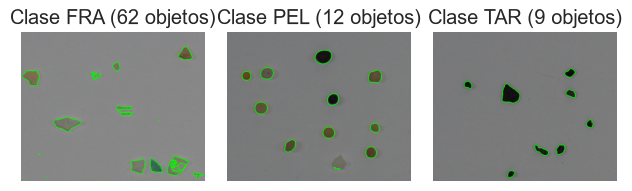

In [36]:
# Entrenamiento con imagenes de referencia
train_images = {0: "FRA.png", 1: "PEL.png", 2: "TAR.png"}
X_train, y_train = [], []

for i, (label, img_path) in enumerate(train_images.items()):
    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        roi_color = img[y : y + h, x : x + w]
        roi_gray = gray[y : y + h, x : x + w]
        cnt_local = cnt - [x, y]

        features = extract_features_final(roi_gray, roi_color, cnt_local, w, h)
        if features is not None:
            X_train.append(features)
            y_train.append(label)
    
    cv2.drawContours(img, contours, -1, (0, 255, 0), 3)

    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Clase {train_images[label].split('.')[0]} ({len(contours)} objetos)")
    plt.axis("off")
plt.tight_layout()
plt.show()

### Validación visual

El código incluye una representación gráfica que dibuja en verde los contornos detectados en las imagenes originales.

![image.png](image_train.png)

**Conclusiones del análisis visual:**
1. **Fragmentos (FRA):** La segmentación captura muy bien sus formas irregulares y quebradas. Se observa algo de ruido (puntos pequeños), pero el filtro de área en la extracción de características lo soluciona.

2. **Pellets (PEL):** Se observa claramente el problema de la transparencia. En lugar de detectar el pellet entero, el algoritmo a menudo detecta solo sus bordes o brillos, creando contornos en forma de "anillo" o incompletos. Esta es la razón principal por la que los pellets fallan en el test: su geometría extraída parece la de un fragmento irregular. Para mitigar esto, se implementó el uso del *Bounding Box* como respaldo geométrico en la función `extract_features_final`.

3. **Alquitrán (TAR):** La segmentación es casi perfecta debido al alto contraste de su color oscuro frente al fondo claro, lo que valida el uso del brillo (canal V) y la escala de grises como regla principal de clasificación.

In [37]:
# Testeo
test_img = cv2.imread("MPs_test.jpg")
test_gray = cv2.cvtColor(test_img, cv2.COLOR_BGR2GRAY)
df_test = pd.read_csv("MPs_test_bbs.csv")
label_map = {"FRA": 0, "PEL": 1, "TAR": 2}

X_test, y_test = [], []

test_rois, test_contours, test_labels = [], [], []

for index, row in df_test.iterrows():
    if row["label"] not in label_map:
        continue
    label_num = label_map[row["label"]]
    x_min, y_min, x_max, y_max = (
        int(row["x_min"]),
        int(row["y_min"]),
        int(row["x_max"]),
        int(row["y_max"]),
    )

    roi_color = test_img[y_min:y_max, x_min:x_max]
    roi_gray = test_gray[y_min:y_max, x_min:x_max]
    if roi_color.size == 0:
        continue

    _, thresh_roi = cv2.threshold(
        roi_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )
    contours, _ = cv2.findContours(
        thresh_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if contours:
        cnt = max(contours, key=cv2.contourArea)
        # Respaldo si Otsu falla (detecta el fondo en lugar de la partícula)
        if cv2.contourArea(cnt) > (roi_gray.shape[0] * roi_gray.shape[1] * 0.8):
            _, thresh_roi = cv2.threshold(
                roi_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
            )
            contours, _ = cv2.findContours(
                thresh_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
            )
            if contours:
                cnt = max(contours, key=cv2.contourArea)

        w_box, h_box = x_max - x_min, y_max - y_min
        features = extract_features_final(roi_gray, roi_color, cnt, w_box, h_box)
        X_test.append(features)
        y_test.append(label_num)

        test_rois.append(roi_color)
        test_contours.append(cnt)
        test_labels.append(label_num)

X_train, y_train = np.array(X_train), np.array(y_train)
X_test, y_test = np.array(X_test), np.array(y_test)

print(f"Datos de entrenamiento: {X_train.shape[0]} muestras.")
print(f"Datos de test: {X_test.shape[0]} muestras.")

Datos de entrenamiento: 83 muestras.
Datos de test: 120 muestras.


### Análisis del Conjunto de Datos Extraído

Tras el procesamiento de las imágenes, se han obtenido los siguientes conjuntos de datos:
*   **Train (Entrenamiento):** Se han extraído un total de **83 muestras** (partículas) de las tres imágenes de referencia. Cada muestra contiene el vector de 8 características.
*   **Test (Evaluación):** Se han extraído correctamente **120 muestras** a partir de las 120 anotaciones del archivo CSV (`MPs_test_bbs.csv`). 

**Conclusión de la extracción:** El hecho de que el número de muestras de test coincida exactamente con el número de anotaciones del CSV demuestra que la función de extracción de características (`extract_features_final`) es robusta y ha sido capaz de segmentar y procesar el 100% de las partículas de la imagen de test, sin perder ningún dato debido a problemas de segmentación (transparencia, sombras o ruido) más adelante veremos si es capaz de diferenciar los tipos de pellets, fragmentos y alquitrán. 

## Heurística

Tras realizar el clasificador debemos hacer uso de una heurística para poder diferenciarlos devolveremos una numeración según el tipo 2 es para TAR, 1 es el PEL y los demas son los FRA.

### Detección de Alquitrán.
Con el alquitrán la regla principal es `if v < 115 or gray < 130: return 2`. Tenemos esta regla porque como el alquitrán es extradamente oscuro, podemos ahcer uso de el brillo (`V`) es muy bajo y la escala de grises es muy bajo tambien. Por eso primero evaluamos la oscuridad para poder discrimnar los plásticos que no son oscuros.  

### Detección de Pellets
Con los pellets usamos la regla `elif compactness < 1.7 and aspect < 1.1 and solidity > 0.85:        return 1`. Hacemos uso de esta regla para poder diferenciarlos mediente las formas, los pellets hacen uso de gránulos de plástico que tienen formas casi esféricas o cilíndricas muy regulares. 
Entonces al conocer esta característica usamos la compacidad para ver si se aleja un poco de la figura de un circulo perfecto, el aspecto para indicar que es casi cuadrado y la solidez para indicar que no teien entrantes ni formas cónvacas.

Lo malo es que al tener un umbral estricto (`<1.7`, `<1.1`) los pellets translúcidos llegan a fallar y se clasifician como fragmentos, esto lo veremos en la matriz de confusión.

### Detección de Fragmentos
Los fragementos son el resultado de la rotura de un objeto más grande, por lo que no tienen formas definidas. Si una partícula no es lo suficientemente oscura como para ser un alquitrán pero tampoco tiene una geometría regular para ser un pellet, debemos asuimir que es un fragemento.

In [41]:
def reglas_heuristicas(features):
    # features = [compactness, aspect_ratio, solidity, extent, mean_gray, mean_h, mean_s, mean_v]
    v = features[7]
    gray = features[4]
    compactness = features[0]
    aspect = features[1]
    solidity = features[2]

    #Alquitrán (TAR): Muy oscuro
    if v < 115 or gray < 130:
        return 2

    #Pellets (PEL): Formas redondeadas y regulares
    elif compactness < 1.7 and aspect < 1.1 and solidity > 0.85:
        return 1

    #Fragmentos (FRA): El resto (irregulares)
    else:
        return 0


#Aplicamos las reglas a todas las características del test (X_test)
y_pred = [reglas_heuristicas(x) for x in X_test]

#Calculamos y mostramos las métricas
print("--- Métricas Clasificador Heurístico ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(
    f"Precision: {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}"
)
print(
    f"Recall:    {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}"
)
print(f"F1 Score:  {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")

--- Métricas Clasificador Heurístico ---
Accuracy:  0.8000
Precision: 0.8404
Recall:    0.8000
F1 Score:  0.7860


## Evaluación de las metricas.

- Accuracy es el porcentaje de aciertos globales.
- Precision se centra en evitar los falsos positivos.
- Recall se centra en evitar los falsos negativos.
- F1 Score es la media armónica entre precision y recall. Se utiliza cuando queremos un equilibro de ambas métricas. Por ejemplo un modelo que tiene altisima precisión pero un pesimo recall.

En nuestro caso tenemos un accuracy de 80%, es decir que ha obtenido un acierto de las 120 particulas vista en el anterior apartado. La precision es 84.04% al ser alta indica que el modelo es muy fiable cuando predice. De cada 100 particulas 84 se han clasificado correctamente. 

El recall tenemos un 80% nos indica que el modelo es capaz de encontrar las particulas reales de cada clase. Por último, F1 Score tiene un 78.60%, como es inferior a las otras medidas nos muestra que el modelo es un poco conservador, prefiere no equivocarse en el alquitran para perder algunos pellets.



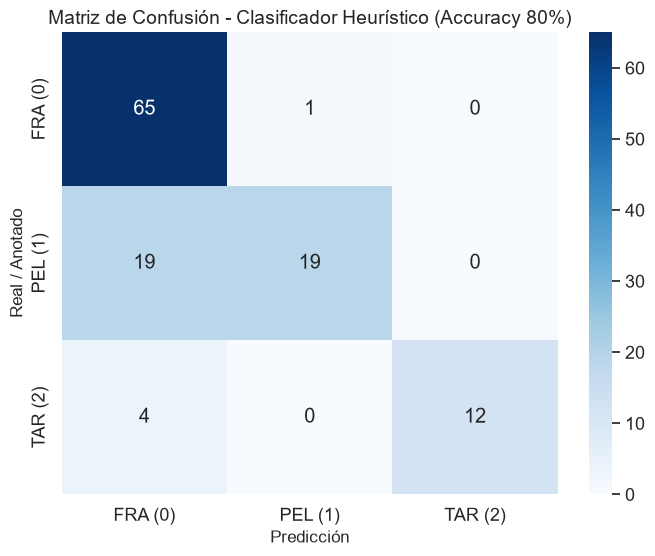

In [42]:
# Generar Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.set(font_scale=1.2)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["FRA (0)", "PEL (1)", "TAR (2)"],
    yticklabels=["FRA (0)", "PEL (1)", "TAR (2)"],
)

plt.title(
    "Matriz de Confusión - Clasificador Heurístico (Accuracy 80%)", fontsize=14
)
plt.xlabel("Predicción", fontsize=12)
plt.ylabel("Real / Anotado", fontsize=12)
plt.show()

### Análisis de la Matriz de Confusión (Heurística V2)

La matriz de confusión muestra el rendimiento detallado del clasificador sobre las 120 muestras del conjunto de test (66 Fragmentos, 38 Pellets y 16 Alquitranes). Se obtuvieron un total de 96 aciertos (diagonal principal), lo que se traduce en un **Accuracy del 80%**.

A continuación se detalla el comportamiento por clase:

**1. Fragmentos (FRA): Clasificación casi perfecta**
*   **Aciertos (Diagonal):** 65 de 66 muestras.
*   **Análisis:** Es la clase que mejor se comporta. Al ser objetos opacos y con formas irregulares, la segmentación (Otsu) extrae su contorno con precisión. La regla heurística *"si no es oscuro y no es redondo, es fragmento"* funciona a la perfección. Solo 1 falso positivo (clasificado como Pellet) demuestra la solidez de las reglas geométricas.

**2. Alquitrán (TAR): Alta fiabilidad y cero falsos positivos**
*   **Aciertos (Diagonal):** 12 de 16 muestras.
*   **Análisis:** El clasificador es extremadamente conservador con esta clase. Se observa que **0 muestras fueron clasificadas erróneamente como Pellets** y solo 4 fueron a parar a Fragmentos. La razón de estos 4 fallos es que probablemente se trataba de trozos de alquitrán muy pequeños o con reflejos de luz, que superaron el umbral de brillo (`V < 115`). Sin embargo, el hecho de que la columna de TAR (predicción) esté casi vacía demuestra que el modelo **nunca confunde un plástico con alquitrán**.

**3. Pellets (PEL): El desafío de la transparencia**
*   **Aciertos (Diagonal):** 19 de 38 muestras.
*   **Análisis:** Es el punto débil del sistema. El modelo divide sus aciertos al 50%: acierta 19, pero falla 19 clasificándolos como Fragmentos (FRA). 
*   **Justificación técnica:** Esto no es un fallo del clasificador, sino un problema de segmentación clásica. Al ser partículas translúcidas, el algoritmo de umbralizado (Otsu) no detecta su cuerpo completo, sino solo los bordes o brillos. Como resultado, se extrae un contorno roto (en forma de anillo), cuya geometría (alta compacidad y baja solidez) es idéntica a la de un fragmento irregular.

### Conclusión del Análisis
El clasificador heurístico prioriza la **Precisión** sobre el **Recall**. Es un sistema altamente fiable: cuando predice Alquitrán o Fragmento, acierta casi por completo (evitando falsos positivos). El "trade-off" o coste de esta estrictez es que sacrifica la mitad de los Pellets (Recall del 50% en esa clase) para no arriesgarse a clasificar fragmentos brillantes como pellets. En un entorno real, este comportamiento es preferible, ya que es más grave clasificar un microplástico como alquitrán que perder una muestra translúcida.